## Apresentação

Este notebook foi criado para mostrar como você pode associar as informações de estratigrafia (intervalos com topo e base) nas profundidades corretas do seu dado. Aqui você precisa de pelo menos dois dados: um que tenha informações relevantes "indexadas" às profundidades e outro com nome das zonas e intervalos de topo e base. Nesse exemplo, atribuiremos zonas existentes a dados com medições de reflectância da vitrinita. Depois de ter aprendido isso, você poderá replicar esse workflow para qualquer tipo de dado (testes de pressão, canhoneios, perfis, etc).

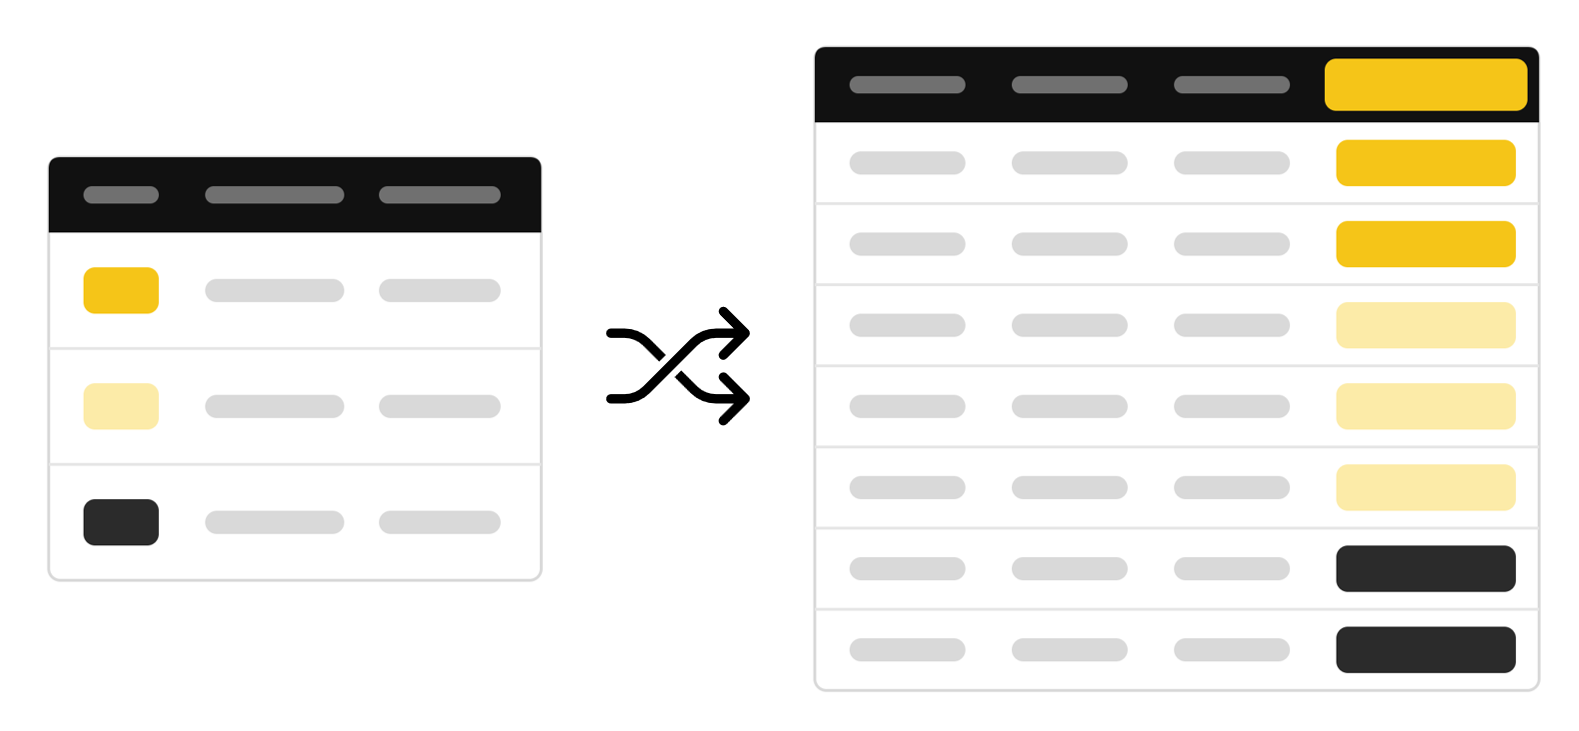

## Descrição do Dado

Esse conjunto de dados pertence ao portal de óleo e gás holandês (https://www.nlog.nl/boringen) e compreende informações de poços situados na região costeira dos Países Baixos no Mar do Norte. Aqui veremos topos e bases de formações estratigráficas, além de dados de reflectância de vitrinita medida por um equipamento chamado Rock-Eval, que realiza medições padrão em material orgânico presente em sedimentos. A partir dessas medições, são obtidas informações sobre o tipo de material orgânico, o grau de maturação térmica e o potencial do sedimento para gerar óleo ou gás.

In [1]:
import numpy as np
import pandas as pd

In [2]:
# Caminho da pasta principal
rootdir = "C:/Users/lucas.aguiar/Desktop/Pastas/B2S/notebooks_exclusivos/3 - Associação de Intervalos de Zonas/"

In [3]:
# Importação do dado de estratigrafia
strat = pd.read_excel(rootdir + "nlog_stratstelsel.xlsx")

C:\Users\pred_\anaconda3\Lib\site-packages\openpyxl\styles\stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [4]:
# Visualização simplificada do dado
print("Data Size (rows, cols):", strat.shape)

strat.head(5)

Data Size (rows, cols): (108389, 27)


,NITG_NR,UWI,WELLBORE,STELSEL,DATA_SOURCE,TOP_AH,BOTTOM_AH,TV_TOP_NAP,TV_BOTTOM_NAP,TV_THICKNESS,...,X_TOP_RD,Y_TOP_RD,X_BOTTOM_RD,Y_BOTTOM_RD,X_TOP_UTM31_WGS84,Y_TOP_UTM31_WGS84,X_BOTTOM_UTM31_WGS84,Y_BOTTOM_UTM31_WGS84,STRAT_SOURCE_CD,LAST_UPDATED
0,BA050018,8438,A05-01,A05-01,A05-01,0.0,1293.0,-36.70,1256.26,1292.96,...,37395.0,857077.0,37404.0,857076.0,532639.0,6170701.0,532648.0,6170701.0,GE-KRT2017RM,2024-04-24 21:03:40.0
1,BA050018,8438,A05-01,A05-01,A05-01,1293.0,1608.5,1256.26,1571.75,315.49,...,37404.0,857076.0,37406.0,857076.0,532648.0,6170701.0,532650.0,6170701.0,GE-KRT2017RM,2024-04-24 21:03:40.0
2,BA050018,8438,A05-01,A05-01,A05-01,1608.5,2459.5,1571.75,2422.72,850.98,...,37406.0,857076.0,37412.0,857079.0,532650.0,6170701.0,532656.0,6170703.0,GE-KRT2017RM,2024-04-24 21:03:40.0
3,BA050018,8438,A05-01,A05-01,A05-01,2459.5,2654.2,2422.72,2617.42,194.70,...,37412.0,857079.0,37413.0,857080.0,532656.0,6170703.0,532657.0,6170704.0,GE-KRT2017RM,2024-04-24 21:03:40.0
4,BA050018,8438,A05-01,A05-01,A05-01,2654.2,2688.0,2617.42,2651.22,33.80,...,37413.0,857080.0,37413.0,857080.0,532657.0,6170704.0,532657.0,6170704.0,GE-KRT2017RM,2024-04-24 21:03:40.0


In [5]:
# Nomes de colunas
strat.columns

Index(['NITG_NR', 'UWI', 'WELLBORE', 'STELSEL', 'DATA_SOURCE', 'TOP_AH',
       'BOTTOM_AH', 'TV_TOP_NAP', 'TV_BOTTOM_NAP', 'TV_THICKNESS',
       'STRAT_UNIT_CD', 'STRAT_UNIT_NM', 'ANOMALY_CD', 'X_TOP_UTM31_ED50',
       'Y_TOP_UTM31_ED50', 'X_BOTTOM_UTM31_ED50', 'Y_BOTTOM_UTM31_ED50',
       'X_TOP_RD', 'Y_TOP_RD', 'X_BOTTOM_RD', 'Y_BOTTOM_RD',
       'X_TOP_UTM31_WGS84', 'Y_TOP_UTM31_WGS84', 'X_BOTTOM_UTM31_WGS84',
       'Y_BOTTOM_UTM31_WGS84', 'STRAT_SOURCE_CD', 'LAST_UPDATED'],
      dtype='object')

In [6]:
# Seleção de colunas importantes (nome do poço, topo da zona, base da zona e nome da zona)
strat = strat[['WELLBORE', 'TOP_AH', 'BOTTOM_AH', 'STRAT_UNIT_NM']]

In [7]:
# Remoção de dados duplicados
strat = strat.drop_duplicates(subset=['WELLBORE', 'TOP_AH', 'BOTTOM_AH', 'STRAT_UNIT_NM'], keep="last")

In [8]:
# Tipo dos dados
strat.dtypes

WELLBORE          object
TOP_AH           float64
BOTTOM_AH        float64
STRAT_UNIT_NM     object
dtype: object

In [9]:
# Importação do dado de reflectância de vitrinita
vitrin = pd.read_excel(rootdir + "nlog_vitriniet.xlsx")

In [10]:
# Visualização simplificada do dado
print("Data Size (rows, cols):", vitrin.shape)

vitrin.head(5)

Data Size (rows, cols): (4280, 18)


,SAMPLE_NR,NITG_NR,UWI,SHORT_NM,TOP_DEPTH,BOTTOM_DEPTH,SAMPLE_TYPE_NM,MEASUREMENT_NR,MEASURED_VALUE_NR,PARAMETER_AND_UNIT,VALUE,EXEC_ORGANISATION,EXEC_PERSON,MEASUREMENT_DATE,QUALITY_LABEL,REMARK,PRESCRIPTION,APPARATUS_NM
0,L1960-00-0001,BB170024,7955,B17-04,182.4,182.4,Gesteente,1,1,"vitrinite reflectance (random, mean) - %Rr",0.28,TNO-NITG,NaN,NaN,NaN,NaN,"Vitriniet Reflectie meting, Random orientatie",Leica_MPV2
1,L1960-00-0002,BB170024,7955,B17-04,243.2,243.2,Gesteente,1,1,"vitrinite reflectance (random, mean) - %Rr",0.28,TNO-NITG,NaN,NaN,NaN,NaN,"Vitriniet Reflectie meting, Random orientatie",Leica_MPV2
2,L1960-00-0003,BB170024,7955,B17-04,364.8,364.8,Gesteente,1,1,"vitrinite reflectance (random, mean) - %Rr",0.32,TNO-NITG,NaN,NaN,NaN,NaN,"Vitriniet Reflectie meting, Random orientatie",Leica_MPV2
3,L1960-00-0004,BB170024,7955,B17-04,425.6,425.6,Gesteente,1,1,"vitrinite reflectance (random, mean) - %Rr",0.28,TNO-NITG,NaN,NaN,NaN,NaN,"Vitriniet Reflectie meting, Random orientatie",Leica_MPV2
4,L1960-00-0005,BB170024,7955,B17-04,547.2,547.2,Gesteente,1,1,"vitrinite reflectance (random, mean) - %Rr",0.33,TNO-NITG,NaN,NaN,NaN,NaN,"Vitriniet Reflectie meting, Random orientatie",Leica_MPV2


In [11]:
# Tipo dos dados
vitrin.dtypes

SAMPLE_NR              object
NITG_NR                object
UWI                     int64
SHORT_NM               object
TOP_DEPTH             float64
BOTTOM_DEPTH          float64
SAMPLE_TYPE_NM         object
MEASUREMENT_NR          int64
MEASURED_VALUE_NR       int64
PARAMETER_AND_UNIT     object
VALUE                 float64
EXEC_ORGANISATION      object
EXEC_PERSON            object
MEASUREMENT_DATE       object
QUALITY_LABEL          object
REMARK                 object
PRESCRIPTION           object
APPARATUS_NM           object
dtype: object

#### Observação
Como o dado de reflectância de vitrinita repete as profundidades de topo e base, entenderemos que cada amostra representa uma profundidade única.

In [12]:
# Criação de dicionários com dataframe por poço
strat_dict = {k : v for k, v in strat.groupby("WELLBORE")}
vitrin_dict = {k : v for k, v in vitrin.groupby("SHORT_NM")}

In [13]:
# Iteração por dicionários e mesma chave (poço)
for k1, v1 in vitrin_dict.items():
    for k2, v2 in strat_dict.items():
        if k1 == k2:

            # Garantindo que os dados estejam com profundidade ordenada, se não pode dar erro depois
            v2 = v2.sort_values(by=['TOP_AH'])

            # Definição dos intervalos das formações
            intervals = v2.set_index(pd.IntervalIndex.from_arrays(
                        v2['TOP_AH'].astype(float),
                        v2['BOTTOM_AH'].astype(float)))['STRAT_UNIT_NM']

            # Associação ao dado de reflectância de vitrinita
            v1['STRAT_UNIT_NM'] = v1["TOP_DEPTH"].map(intervals)

            # Atualização do dicionário com novo dado
            vitrin_dict[k1] = v1           

In [14]:
# Concatenação de dados e agora teremos a coluna de formação STRAT_UNIT_NM na última posição do dataframe
vitrin_concat = pd.concat(vitrin_dict, ignore_index=True)

vitrin_concat.head(5)

,SAMPLE_NR,NITG_NR,UWI,SHORT_NM,TOP_DEPTH,BOTTOM_DEPTH,SAMPLE_TYPE_NM,MEASUREMENT_NR,MEASURED_VALUE_NR,PARAMETER_AND_UNIT,VALUE,EXEC_ORGANISATION,EXEC_PERSON,MEASUREMENT_DATE,QUALITY_LABEL,REMARK,PRESCRIPTION,APPARATUS_NM,STRAT_UNIT_NM
0,L2005-05-0312,BA110040,7000,A11-01,3654.55,NaN,Cutting,1,1,"vitrinite reflectance (maximum, mean) - %Rmax",0.344105,TNO-NITG,Veld,2005-07-15 00:00:00.0,+++,Brown coal ?; QUALITY_LABEL: QC(vitrinite refl...,"Vitriniet Reflectie meting, Random orientatie ...",Leica_MPV2,Z2 Carbonate Member
1,L2005-05-0312,BA110040,7000,A11-01,3654.55,NaN,Cutting,1,2,vitrinite reflectance - standard deviation % Rmax,0.106848,TNO-NITG,Veld,2005-07-15 00:00:00.0,+++,Brown coal ?; QUALITY_LABEL: QC(vitrinite refl...,"Vitriniet Reflectie meting, Random orientatie ...",Leica_MPV2,Z2 Carbonate Member
2,L2005-05-0312,BA110040,7000,A11-01,3654.55,NaN,Cutting,1,3,number of measurements,19.000000,TNO-NITG,Veld,2005-07-15 00:00:00.0,+++,Brown coal ?; QUALITY_LABEL: QC(vitrinite refl...,"Vitriniet Reflectie meting, Random orientatie ...",Leica_MPV2,Z2 Carbonate Member
3,L2005-05-0313,BA110040,7000,A11-01,3666.74,NaN,Cutting,1,1,"vitrinite reflectance (maximum, mean) - %Rmax",0.613933,TNO-NITG,Veld,2005-07-15 00:00:00.0,NaN,2 populations; Kwaliteit van de meting=mp; 0,"Vitriniet Reflectie meting, Random orientatie ...",Leica_MPV2,Z1 Anhydrite Member
4,L2005-05-0313,BA110040,7000,A11-01,3666.74,NaN,Cutting,1,2,vitrinite reflectance - standard deviation % Rmax,0.426405,TNO-NITG,Veld,2005-07-15 00:00:00.0,NaN,2 populations; Kwaliteit van de meting=mp; 0,"Vitriniet Reflectie meting, Random orientatie ...",Leica_MPV2,Z1 Anhydrite Member


In [15]:
# Exportando novo dado
vitrin_concat.to_excel(rootdir + "nlog_vitriniet_edit.xlsx", index=False)